## 🔊 - Noise-only simulation

Play with and visualize `NoiseConfig` in isolation, with no spike/signal present --
useful for building intuition about the calibrated background noise floor before
adding a source on top (see `simulation_spike.ipynb`).

- `fwd`: Forward Solution
- `con`: Structural Connectivity
- `eeg`: EEG template
- `parc`: Parcellation
- `ras2tkras`: subject to freesurfer transform

In [1]:
import matplotlib.pyplot as plt
import mindmap as mm
import numpy as np
import mne

# data manager
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

# data
fwd = dm.load(sub, "fwd", desc="sim")
con = dm.load(sub, "con")
eeg = dm.load(sub, "ave-temp")
parc = dm.load(sub, "dseg", space="fs", segmentation="multiconn2022", scale="4")
ras2tkras = dm.load(sub, "ras2tkras")

## 🧬 - Data Processing

Build a noise-only simulation: a zero-amplitude source, so only `NoiseConfig`'s
calibrated background remains in the delivered recording.

In [2]:
# Noise-only "source": zero amplitude, but keeps the same event/onset
# structure as a real spike so we still get epochable event markers --
# mirrors mindmap.analysis.simulation.pipeline._zero_scale_source. Location
# is irrelevant here since scale=0 means nothing actually propagates.
noise_signal = mm.analysis.simulation.SpikeSignal(
    width = 0.1,
    onset = 0.5,
    repeat = 1,
    scale = 0,
    event_id = 1,
)

noise_source = mm.analysis.simulation.Source(
    locations = ["ctx-rh-lateralorbitofrontal_3"],
    signal = noise_signal,
)

# head model
head_model = mm.analysis.simulation.HeadModel(
    sensors = eeg,
    forward = fwd,
    connectivity_weights = con > 0,
    connectivity_lengths = con,
    parcellation = parc,
    ras2tkras = ras2tkras,
)

# Epoch configuration
epoch_config = mm.analysis.simulation.EpochConfig(
    tmin = -0.45,
    tmax = 0.45,
    baseline = (-0.45, -0.2),
    signal_window = (-0.1, 0.45),
)

# Propagation configuration -- irrelevant here (there's no signal to
# propagate), kept only because Simulator.run requires one.
prop_config = mm.analysis.simulation.PropagationConfig()

sim = mm.analysis.simulation.Simulator(head_model, epoch_config)

## 🎛️ - Noise configuration

- `sensor_noise_scale_uv`: small, FIXED instrument/electrode-noise floor -- a
  property of the recording hardware, independent of the forward model.
- `target_sensor_noise_uv`: TOTAL desired sensor-level background (literature
  midpoint for scalp EEG, ~10-20uV RMS).

`dipole_noise`'s Am-scale is SOLVED at run time so this head model's
forward-projected contribution makes up the rest of the target, regardless of
this source's particular forward gain -- see `sim.last_dipole_noise_scale`
after running.

In [3]:
noise_config = mm.analysis.simulation.NoiseConfig()
noise_config

NoiseConfig(sensor_noise_scale_uv=2.0, target_sensor_noise_uv=15.0, sensor_noise_color='white', dipole_noise_color='pink')

Run simulation.

In [4]:
gold, raw = sim.run(noise_source, prop_config, snr_target=None, noise_config=noise_config)
print(f"Solved dipole_noise scale: {sim.last_dipole_noise_scale:.2e} Am")

Solved dipole_noise scale: 3.78e-09 Am


## 📊 - Visualization
Raw trace (a few channels).

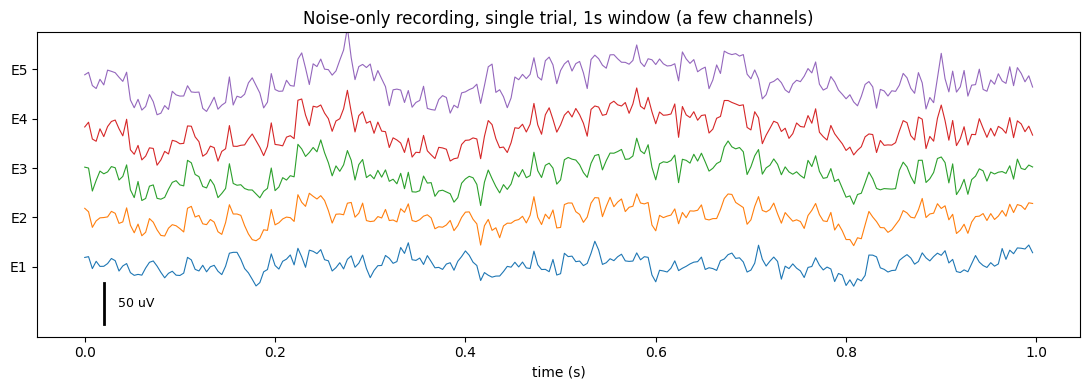

In [5]:
picks = mne.pick_types(raw.info, eeg=True)[:5]
data, times = raw.get_data(picks=picks, tmin=0.0, tmax=1.0, return_times=True)
data = data * 1e6  # uV

fig, ax = plt.subplots(figsize=(11, 4))
offsets = np.arange(len(picks)) * 60  # uV spacing between traces (visual separation only)
for i, ch_idx in enumerate(picks):
    ax.plot(times, data[i] + offsets[i], lw=0.8)
ax.set_yticks(offsets)
ax.set_yticklabels([raw.ch_names[i] for i in picks])
ax.set_xlabel("time (s)")
ax.set_title("Noise-only recording, single trial, 1s window (a few channels)")

# Traces are offset for visual separation, so a plain y-axis in uV would be
# ambiguous (the offset itself isn't an amplitude) -- add an explicit
# vertical scale bar instead, giving a direct, unambiguous reference.
scale_uv = 50
x0 = times[0] + 0.02
y0 = -70
ax.plot([x0, x0], [y0, y0 + scale_uv], color="black", lw=2)
ax.text(x0 + 0.015, y0 + scale_uv / 2, f"{scale_uv} uV", va="center", ha="left", fontsize=9)
ax.set_ylim(y0 - 15, offsets[-1] + 45)

plt.tight_layout()

Global Field Power: single trial vs. averaged across repeats.

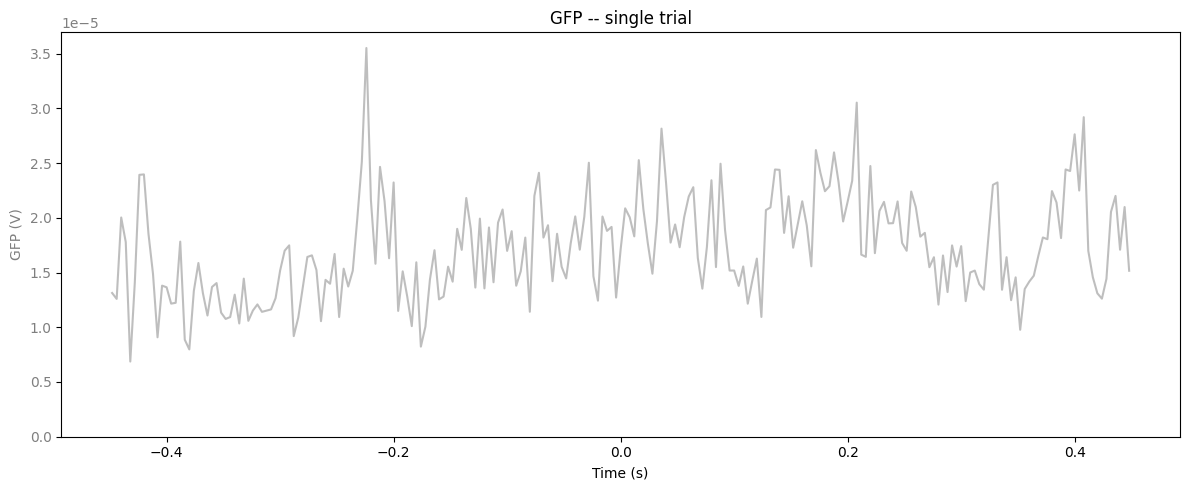

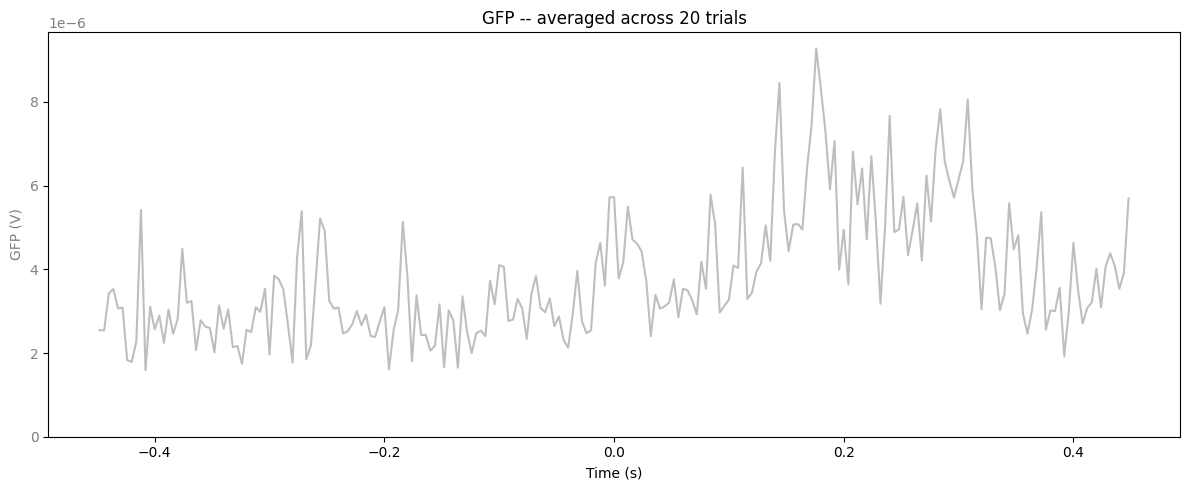

In [6]:
events = mne.events_from_annotations(raw, verbose="warning")[0]
epochs = mne.Epochs(
    raw, events,
    tmin = epoch_config.tmin,
    tmax = epoch_config.tmax,
    baseline = epoch_config.baseline,
    preload = True,
    verbose = "warning",
)

single_trial = epochs[0].average()
averaged = epochs.average()

# plot_gfp closes its figure internally before returning it, so it needs an
# explicit display() to show up here (a bare/last-expression call wouldn't).
from IPython.display import display
display(mm.viz.plot_gfp(single_trial, title="GFP -- single trial"))
display(mm.viz.plot_gfp(averaged, title=f"GFP -- averaged across {len(epochs)} trials"))

Power spectrum: pink (dipole background) + white (sensor) noise, combined.

Plotting power spectral density (dB=True).


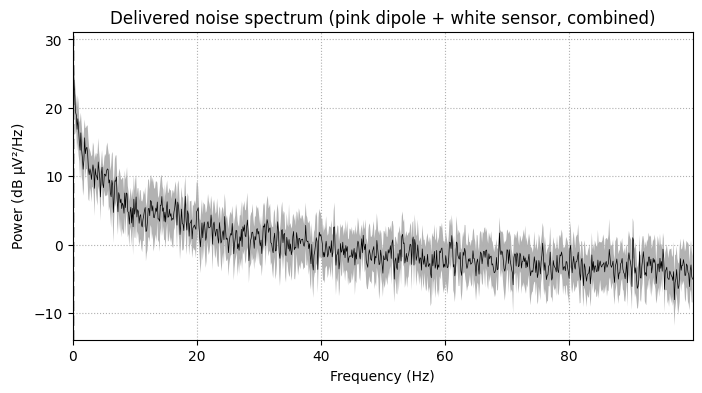

In [7]:
spectrum = raw.compute_psd(picks="eeg", fmax=100, verbose="warning")
fig, ax = plt.subplots(figsize=(8, 4))
spectrum.plot(average=True, axes=ax, show=False)
ax.set_title("Delivered noise spectrum (pink dipole + white sensor, combined)");

Baseline amplitude check (uV).

In [8]:
rms_uv = mm.analysis.eeg.estimate_raw_baseline_rms(
    raw, events=events, event_id=1,
    tmin = epoch_config.tmin,
    tmax = epoch_config.tmax,
    baseline = epoch_config.baseline,
    picks = "eeg",
)
print(
    f"Delivered baseline RMS: median={np.median(rms_uv):.1f}uV, max={rms_uv.max():.1f}uV "
    f"across channels (target was {noise_config.target_sensor_noise_uv}uV; "
    "literature scalp background: ~10-20uV RMS)"
)

Delivered baseline RMS: median=15.0uV, max=18.3uV across channels (target was 15.0uV; literature scalp background: ~10-20uV RMS)


## 🎛️ - Play with `NoiseConfig`

Two independent knobs, one target: sweep `target_sensor_noise_uv` (the total
background level) and, separately, sweep how that same total is *split*
between the fixed hardware floor (`sensor_noise_scale_uv`) and the solved-for
background-activity contribution (`dipole_noise_scale`).

In [9]:
print(f"{'target_sensor_noise_uv':>25} {'dipole_noise_scale':>20} {'delivered RMS (uV)':>20}")
for target_uv in [5.0, 15.0, 30.0]:
    cfg = mm.analysis.simulation.NoiseConfig(target_sensor_noise_uv=target_uv)
    _, raw_i = sim.run(noise_source, prop_config, snr_target=None, noise_config=cfg)
    ev_i = mne.events_from_annotations(raw_i, verbose="warning")[0]
    rms_i = mm.analysis.eeg.estimate_raw_baseline_rms(
        raw_i, events=ev_i, event_id=1,
        tmin=epoch_config.tmin, tmax=epoch_config.tmax, baseline=epoch_config.baseline, picks="eeg",
    )
    print(f"{target_uv:25.1f} {sim.last_dipole_noise_scale:20.2e} {np.median(rms_i):20.1f}")

   target_sensor_noise_uv   dipole_noise_scale   delivered RMS (uV)


                      5.0             1.15e-09                  5.0


                     15.0             3.71e-09                 15.0


                     30.0             7.57e-09                 30.0


Fixed total, different split between hardware noise and background activity -- `dipole_noise_scale` shrinks to compensate as `sensor_noise_scale_uv` grows, keeping the delivered total on target.

In [10]:
print(f"{'sensor_noise_scale_uv':>23} {'dipole_noise_scale':>20} {'delivered RMS (uV)':>20}")
for sensor_uv in [1.0, 8.0, 14.0]:
    cfg = mm.analysis.simulation.NoiseConfig(sensor_noise_scale_uv=sensor_uv, target_sensor_noise_uv=15.0)
    _, raw_i = sim.run(noise_source, prop_config, snr_target=None, noise_config=cfg)
    ev_i = mne.events_from_annotations(raw_i, verbose="warning")[0]
    rms_i = mm.analysis.eeg.estimate_raw_baseline_rms(
        raw_i, events=ev_i, event_id=1,
        tmin=epoch_config.tmin, tmax=epoch_config.tmax, baseline=epoch_config.baseline, picks="eeg",
    )
    print(f"{sensor_uv:23.1f} {sim.last_dipole_noise_scale:20.2e} {np.median(rms_i):20.1f}")

  sensor_noise_scale_uv   dipole_noise_scale   delivered RMS (uV)


                    1.0             3.91e-09                 14.9


                    8.0             3.28e-09                 14.9


                   14.0             1.39e-09                 14.7


Noise color: pink vs. white background (cortical) activity.

Plotting power spectral density (dB=True).


Plotting power spectral density (dB=True).


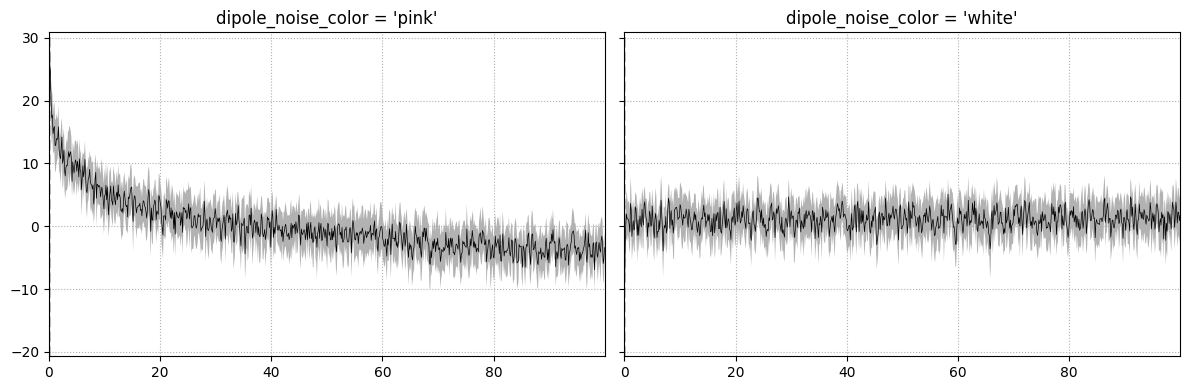

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, color in zip(axes, ["pink", "white"]):
    cfg = mm.analysis.simulation.NoiseConfig(dipole_noise_color=color)
    _, raw_i = sim.run(noise_source, prop_config, snr_target=None, noise_config=cfg)
    spec = raw_i.compute_psd(picks="eeg", fmax=100, verbose="warning")
    spec.plot(average=True, axes=ax, show=False)
    ax.set_title(f"dipole_noise_color = '{color}'")
plt.tight_layout()